In [7]:
import numpy as np
import matplotlib.pyplot as plt

In [8]:
def fitness(x):
  delay = x[0]
  energy = x[1]
  return 0.6 * delay + 0.4 * energy

In [9]:
num_particles = 5
num_dimensions = 2
max_iter = 20
c1 = 2.0
c2 = 2.0
w = 0.7

In [11]:
x = np.random.uniform(low=[8, 3], high=[15, 6], size=(num_particles, num_dimensions))
v = np.zeros_like(x)

In [12]:
p_best = x.copy()
p_best_fitness = np.array([fitness(p) for p in p_best])

g_best = p_best[np.argmin(p_best_fitness)]
g_best_fitness = np.min(p_best_fitness)

history = []

In [14]:
for t in range(max_iter):
  for i in range(num_particles):
    r1, r2 = np.random.rand(), np.random.rand()

    v[i] = (
        w * v[i]
        + c1 * r1 * (p_best[i] - x[1])
        + c2 * r2 * (g_best - x[i])
    )

    x[i] = x[i] + v[i]

    f = fitness(x[i])

    if f  < p_best_fitness[i]:
      p_best[i] = x[i]
      p_best_fitness[i] = f

  min_index = np.argmin(p_best_fitness)
  if p_best_fitness[min_index] < g_best_fitness:
    g_best = p_best[min_index]
    g_best_fitness = p_best_fitness[min_index]

  history.append(g_best_fitness)
  print(f"Iterasi {t+1:02d}: Global Best Fitness = {g_best_fitness:.4f}, Posisi = {g_best}")

Iterasi 01: Global Best Fitness = 6.8942, Posisi = [8.04316546 5.17083404]
Iterasi 02: Global Best Fitness = 6.5609, Posisi = [6.31088414 6.93592541]
Iterasi 03: Global Best Fitness = 3.2878, Posisi = [1.10414508 6.56336346]
Iterasi 04: Global Best Fitness = -3.0615, Posisi = [-9.1363704  6.0509226]
Iterasi 05: Global Best Fitness = -16.9080, Posisi = [-28.61267634   0.64905352]
Iterasi 06: Global Best Fitness = -31.2323, Posisi = [-48.00227332  -6.07721752]
Iterasi 07: Global Best Fitness = -48.0945, Posisi = [-70.07859344 -15.11824991]
Iterasi 08: Global Best Fitness = -59.8980, Posisi = [-85.53201753 -21.44697258]
Iterasi 09: Global Best Fitness = -74.1263, Posisi = [-103.93942222  -29.40670164]
Iterasi 10: Global Best Fitness = -104.7107, Posisi = [-143.03146298  -47.22959349]
Iterasi 11: Global Best Fitness = -131.4387, Posisi = [-176.43606387  -63.9427539 ]
Iterasi 12: Global Best Fitness = -149.6158, Posisi = [-199.48042086  -74.81881447]
Iterasi 13: Global Best Fitness = -258.2

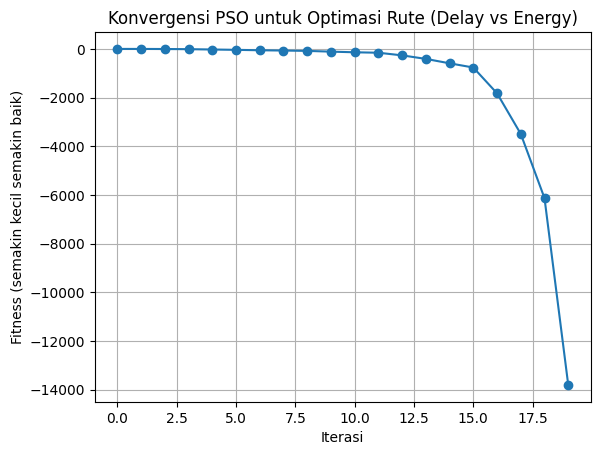

In [16]:
plt.plot(history, marker='o')
plt.title("Konvergensi PSO untuk Optimasi Rute (Delay vs Energy)")
plt.xlabel("Iterasi")
plt.ylabel("Fitness (semakin kecil semakin baik)")
plt.grid(True)
plt.show()